## Cell 1: Core Imports and Project Setup

This block imports all necessary libraries, establishing the core technical stack for this advanced PINN framework. The imports can be grouped into four categories.

### 1. JAX and Flax (The Core Engine)
* `jax`, `jax.numpy`, `flax`: This is the foundation of the model.
    * **JAX** provides the high-performance, function-based autodifferentiation engine.
    * **Flax (`linen as nn`)** is the neural network library used to define the PINN architecture (e.g., the MLP).

### 2. Optimizers (The "How-to-Train" Strategy)
This is a key section, as it imports the components for the hybrid optimization strategy discussed in the JCP paper (Urbán et al., 2025).
* **`optax`**: Imports the standard, first-order optimizer (`Adam`). This is typically used for the initial phase of training to robustly find a good local minimum.

### 3. Custom "Crunch" Library (The Project's Novelty)
This is the project-specific library containing your custom, state-of-the-art implementations.
* **`Crunch.Models.layers`**: This is a critical import for the `Patcher Agent`. It contains your custom layer definitions, such as **Fourier Embeddings, KANs, KKANs, and RBFs**. If a user wants to "use a KAN," the `Patcher` knows to target this.
* **`Crunch.Optimizers.minimize`**: This is the core of your novel optimization. It imports your custom implementation of **`SSBroyden`** (Self-Scaled Broyden), which the JCP paper identified as a state-of-the-art method for overcoming ill-conditioning and achieving superior accuracy.
* `Crunch.Auxiliary.utils`: Imports helpers for the custom optimizer.

### 4. Data Handling and Utilities
* **`scipy.io as sio`**: Used to load the ground-truth solution from `.mat` files.
* **`pyDOE.lhs`**: Imports **Latin Hypercube Sampling (LHS)**. This is the function used to generate the quasi-random collocation points for training the PDE residual.
* `matplotlib`: Standard library for plotting results.
* `tqdm`: For generating progress bars.

In [1]:
import os
import sys
import time
import random
from functools import partial
from typing import Sequence, Callable 

# --- JAX, Flax, and Optax ---
import jax
import jax.numpy as jnp
from jax import Array
from jax import jit, jvp, vjp, value_and_grad, lax, vmap
from jax.flatten_util import ravel_pytree
from flax import linen as nn
import optax

# --- NumPy, SciPy, and Plotting ---
import numpy as np
import scipy
import scipy.io as sio
from scipy import sparse
from scipy.linalg import cholesky, LinAlgError
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.colors as colors

# --- Other Third-Party ---
from tqdm import tqdm
from pyDOE import lhs

# --- Local Application Libraries ---
from Crunch.Models.layers import * 
from Crunch.Auxiliary.metrics import relative_l2 
from Crunch.Optimizers.minimize import minimize
from Crunch.Auxiliary.utils import static_options_SSBroyden

## Data Type

We will work with a Second-Order Optimizer so we need to activate double precision

In [2]:
#from jax import config
jax.config.update("jax_enable_x64", True)
# force jax to use one device
os.environ["CUDA_VISIBLE_DEVICES"]="0"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"]="false"

"""
## Cell 2: Hyperparameter Configuration (argparse)

This block uses `argparse` to define all tunable parameters for the experiment. It is the **primary target for the Patcher Agent** when a user requests a modification to the model or training process.

The parameters are grouped into four logical categories, which are then assigned to local variables.

### 1. Data and Batching
* `NC` (Number of Collocation points): The total number of points sampled inside the spatio-temporal domain to train the PDE residual.
* `NI` (Number of Initial points): Number of points sampled at `t=0` for the initial condition.
* `NB` (Number of Boundary points): Number of points sampled at the spatial boundaries (`x=-1`, `x=1`) for the boundary conditions.
* `batch_size`: The batch size used for the **second-stage (SSBroyden)** optimizer.

### 2. Representation Model (The "What")
This defines the general **Function Approximator architecture**, as discussed in the `PINNs_Review_Journal.pdf`. This is not necessarily a standard MLP; it could be any model from the `Crunch.Models.layers` import (e.g., MLP, PIKAN, RBF).
* `N_LAYERS`: The number of hidden layers in the approximator.
* `HIDDEN`: The number of neurons (or basis functions) in each hidden layer.
* `embedding_degree`: The degree for the input feature expansion (e.g., Fourier or polynomial features). This is a key technique reviewed in the `PINNs_Review_Journal.pdf` to help the model capture high-frequency components.

### 3. 1st Stage Optimization (Adam + vRBA)
This section controls the initial training phase, which uses the `Adam` optimizer combined with the `vRBA` loss function.
* `EPOCHS`: Number of `Adam` training iterations.
* `LR` (Learning Rate): The initial learning rate for the `Adam` optimizer.
* `decay_step`, `decay_rate`: Parameters for an exponential learning rate decay schedule.

#### vRBA Parameters
These are the core parameters for the **variational Residual-Based Attention (vRBA)** loss function, as defined in our `vRBA.pdf`.
* `phi`, `c_log`: Key parameters that define the convex transformation of the residual. `phi=1, c_log=1` corresponds to the exponential weighting (`exp(r)`), which targets the **uniform $L^{\infty}$ error**.
* `eta`, `gamma`, `alpha`: Learning rates and decay factors for the internal moving averages of the vRBA algorithm.
* `max_RBA0`, `cap_RBA`: Parameters that cap the residual weights to ensure training stability.
* `gamma_grads`: Decay rate for the self-scaling algorithm that automatically tunes the loss weights.

### 4. 2nd Stage Optimization (SSBroyden + Sampling)
This section controls the second, high-precision training phase, which uses our custom `SSBroyden` optimizer from the `Crunch` library.
* `Nbfgs`: The total number of iterations for the `SSBroyden` optimizer.
* `Nchange`: The number of `SSBroyden` steps to perform before re-sampling the collocation points.
* `k_samp_bfgs`, `c_samp_f`: Parameters that control the adaptive *re-sampling* strategy used during this phase. This focuses the optimizer on regions of high error.

### 5. Experiment Seeding and Naming
* `SEED`: The master random seed for both `JAX` and `NumPy` to ensure reproducibility.
* `args.Name`: A string that automatically generates a unique experiment name by combining the most important hyperparameters. This is crucial for logging and comparing results.
"""

In [3]:
import argparse
# Set up argument parser
parser = argparse.ArgumentParser(description='Tuning Parameters')
parser.add_argument('--Equation', type=str, default='Allen_Cahn', help='Name of equation')
parser.add_argument('--Name', type=str, default='SS_Broyden', help='Name of the experiment')
parser.add_argument('--NC', type=int, default=200000, help='Number of samples for training')
parser.add_argument('--NI', type=int, default=512, help='Number of iterations')
parser.add_argument('--NB', type=int, default=512, help='Batch size')
parser.add_argument('--NC_TEST', type=int, default=100, help='Number of test samples')
parser.add_argument('--SEED', type=int, default=9999, help='Random seed')
parser.add_argument('--EPOCHS', type=int, default=20000, help='Number of training epochs')
parser.add_argument('--N_LAYERS', type=int, default=3, help='Number of layers in the network')
parser.add_argument('--HIDDEN', type=int, default=30, help='Number of hidden units per layer')
parser.add_argument('--FEATURES', type=int, default=1, help='Feature size')
parser.add_argument('--embedding_degree', type=int, default=1, help='Degree of features')
parser.add_argument('--lr_fact', type=float, default=0.2, help='Scale Lr')
parser.add_argument('--eta', type=float, default=0.01, help='Learning rate or step size for adaptive gamma')
parser.add_argument('--gamma', type=float, default=0.999, help='Decay rate for adaptive gamma')
parser.add_argument('--gamma_bfgs', type=float, default=0.1, help='Decay rate for adaptive gamma')
parser.add_argument('--gamma_grads', type=float, default=0.99, help='Decay rate for adaptive gamma')
parser.add_argument('--alpha', type=float, default=1.0, help='Decay rate for exponential moving average')
parser.add_argument('--cap_RBA', type=float, default=20, help='Cap limit for RBA')
parser.add_argument('--max_RBA', type=float, help='Maximum RBA value, default calculated as eta / (1 - gamma)')
parser.add_argument('--decay_rate', type=float, default=0.9, help='Decay rate for learning rate schedule')
parser.add_argument('--LR', type=float, default=1e-3, help='Initial learning rate')
parser.add_argument('--decay_step', type=int,default=5000, help='Decay step size')
parser.add_argument('--Note', type=str, default='', help='In case')
parser.add_argument('--batch_size', type=int, default=20000, help='batch_size')
parser.add_argument('--k_samp', type=float, default=1.0, help='Enhance outliers smoothing factor')
parser.add_argument('--c_samp', type=float, default=0.0, help='homogenize')
parser.add_argument('--phi', type=float, default=1, help='Enhance outliers smoothing factor')
parser.add_argument('--c_log', type=float, default=1.0, help='homogenize')
parser.add_argument('--N_change', type=int, default=100, help='homogenize')

# Parse arguments and display them
args, unknown = parser.parse_known_args()
for arg, value in vars(args).items():
    print(f'{arg}: {value}')

# Data
NC = args.NC
NI = args.NI
NB = args.NB
NC_TEST = args.NC_TEST

#Representation Model

#- Input transfromations
embedding_degree = args.embedding_degree
# - Architecture
N_LAYERS = args.N_LAYERS # Number of Layers
HIDDEN = args.HIDDEN #hidden neurons per layer
FEATURES = args.FEATURES # Number of output fetures

# - 1st Stage Optmization
## Adam
EPOCHS = args.EPOCHS
eta = args.eta
decay_rate = args.decay_rate
LR = args.LR
lr0 = LR
decay_step = args.decay_step
## vRBA Params
gamma = args.gamma
alpha = args.alpha
c_log=args.c_log
phi=args.phi
##  We use a self scaling algoirhtm to automatically tune the global weights and to increase the cap of RBA to improve learning dunamics
max_RBA0 = args.max_RBA if args.max_RBA is not None else eta / (1 - gamma)
cap_RBA = args.cap_RBA
gamma_grads=args.gamma_grads
## vRBA Params Second order_ Sampling + SSBroycen
k_samp_bfgs = args.k_samp
c_samp_bfgs = args.c_samp
Nchange = args.N_change  # Number of SSBroyden steps before resampling
batch_size=args.batch_size 
Nbfgs=100000 # Number of SSBroyden BFGs iterations


# random key
SEED = args.SEED
key = jax.random.PRNGKey(SEED)
key, subkey = jax.random.split(key, 2)
# Initialize NumPy seed
np.random.seed(SEED)
# Name of the project
args.Name=args.Name+f'vRBA-phi:{phi:.2f}-c_log:{c_log:.2f}-bs:{batch_size}_k:{k_samp_bfgs:.2f}_N:{Nchange:.2f}_Seed:{SEED}'+args.Note
print(args.Name)
#Define folder
file_path = os.getcwd()
project_root = os.path.dirname(os.path.dirname(file_path))
args.Name =project_root+'/Results/'+args.Equation+'/'+args.Name+'/'

Equation: Allen_Cahn
Name: SS_Broyden
NC: 200000
NI: 512
NB: 512
NC_TEST: 100
SEED: 9999
EPOCHS: 20000
N_LAYERS: 3
HIDDEN: 30
FEATURES: 1
embedding_degree: 1
lr_fact: 0.2
eta: 0.01
gamma: 0.999
gamma_bfgs: 0.1
gamma_grads: 0.99
alpha: 1.0
cap_RBA: 20
max_RBA: None
decay_rate: 0.9
LR: 0.001
decay_step: 5000
Note: 
batch_size: 20000
k_samp: 1.0
c_samp: 0.0
phi: 1
c_log: 1.0
N_change: 100
SS_BroydenvRBA-phi:1.00-c_log:1.00-bs:20000_k:1.00_N:100.00_Seed:9999


## Cell 3: Data Loading and Ground Truth Definition

This block loads the high-resolution "ground truth" solution for the Allen-Cahn equation from a pre-computed `.mat` file. This data is used for two purposes:
1.  Setting the Initial and Boundary Conditions (ICs/BCs).
2.  Evaluating the model's final `L2` error against the "true" solution.

### Data Loading
* `data = scipy.io.loadmat(...)`: Loads the `.mat` file containing the solution.
* `Exact = data['usol'].T`: Extracts the solution and transposes it to match the `(time, space)`-first convention.
* `Exact0`: The final, clean ground-truth data array.
* `t0`, `x0`: The 1D vectors for the time and space coordinates.
* `T`, `X`: A 2D `meshgrid` of the `t` and `x` coordinates. This is the grid that `Exact0` is defined on.

### Flattened Ground Truth (for Testing)
* `t`, `x`, `u_gt`: These are the flattened versions of the grid and solution. They are zipped together to create the final test dataset, which is used to calculate the model's error at the end of training.

---

### **Critical Note for Agents (Patcher and Validator)**

This block represents one of two possible scenarios for defining the ground truth:

**Scenario A: Data-Driven (This File)**
* The problem uses synthetic, pre-computed data.
* **Patching:** If the user provides a *new* problem (e.g., "Burgers' equation"), the `Patcher Agent` must change `allen_cahn.mat` to the correct file (e.g., `burgers.mat`) from the `available_data_sets_path`.

**Scenario B: Analytical Solution (e.g., `u(x,t) = sin(pi*x)*cos(pi*t)`)**
* In this case, no `.mat` file exists.
* **Patching:** The `Patcher Agent` must **delete this entire `scipy.io.loadmat` block**.
* It must be **replaced** with new code that:
    1.  Defines the domain (e.g., `t0 = jnp.linspace(0, 1, 100)`, `x0 = jnp.linspace(-1, 1, 256)`).
    2.  Creates the `T, X` meshgrid.
    3.  Generates `Exact0` and `u_gt` by evaluating the user-provided analytical function (e.g., `Exact0 = jnp.sin(jnp.pi * X) * jnp.cos(jnp.pi * T)`).
"""

In [4]:
available_data_sets_path='/users/jdtoscan/data/jdtoscan/LLM/Documents/codes/Data/'
data = scipy.io.loadmat(available_data_sets_path+'allen_cahn.mat')
print(data.keys())
Exact = data['usol'].T
Exact0 = np.real(Exact).astype(jnp.float64)  
t0 = data['t'].flatten()[:,None].astype(jnp.float64)     
x0 = data['x'].flatten()[:,None].astype(jnp.float64)    
T, X = np.meshgrid(t0, x0)
# Ground Truth (to compute relative errors)
t = T.flatten()[:,None]
x = X.flatten()[:,None]
u_gt = Exact0.flatten()[:,None]

dict_keys(['__header__', '__version__', '__globals__', 't', 'usol', 'x'])



## Cell 4: Data Processing, Sampling, and Visualization

This block prepares the raw data from Cell 3 into distinct training datasets for the PINN. It generates the three main types of training points required:
1.  **Collocation Points** (for the PDE residual)
2.  **Initial Condition Points** (for `t=0`)
3.  **Boundary Condition Points** (for the spatial boundaries)

Finally, it plots the data for human verification.

### 1. Domain and Collocation Points
* `lb_D`, `ub_D`: Defines the lower (`lb`) and upper (`ub`) bounds of the spatio-temporal domain `[t, x]`. These are extracted directly from the loaded data.
* `X_c`: The main **Collocation Points**. These are the `NC` points sampled from *inside* the domain.
* `lhs(2, NC)`: This is the **Latin Hypercube Sampling (LHS)** function, an efficient method for quasi-random sampling that ensures points are well-distributed. `NC` is set in the `argparse` cell (Cell 2).
* `tc`, `xc`: The final time and space coordinates for the collocation points.

### 2. Initial and Boundary Conditions
* **Initial Conditions (IC):** `ti`, `xi`, `ui`
    * This is a **data-driven** IC. The initial state (`t=0`) is extracted from the first time-slice of the ground truth data (`Exact0[:, 0:1]`).
* **Boundary Conditions (BC):** `tb`
    * Boundary points are sampled along the time axis using `jax.random.uniform`.
    * *Note:* For this Allen-Cahn problem with periodic BCs, this data is not explicitly passed to the loss. For a problem with **Dirichlet BCs**, this tuple would also need to include the spatial coordinates (`xb`) and target values (`ub`).

### 3. Final Data Tuples
* `train_data`: This tuple (`tc, xc, ti, xi, ui`) bundles the data for the training function.
* **FLEXIBILITY NOTE:** This tuple is flexible and problem-dependent.
    * For **Dirichlet BCs**, it would be expanded to include boundary data (e.g., `tc, xc, ti, xi, ui, tb, xb, ub`).
    * For **Inverse Problems**, it would also include any available observational data (e.g., `t_obs, x_obs, u_obs`) to be passed to the data-loss term.

### 4. Visualization
* The `matplotlib` code generates two plots for human-in-the-loop verification:
    1.  **Scatter Plot:** Shows the distribution of the Collocation, Initial, and Boundary points.
    2.  **Contour Plot:** Shows the "Exact Solution" (`Exact0`) to verify the correct data was loaded.


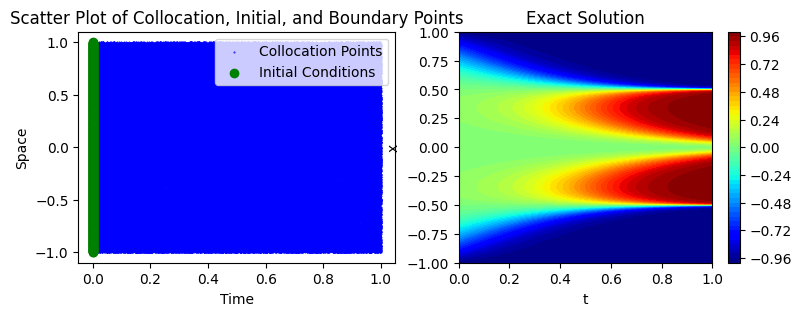

In [5]:
# Collocation points
lb_D = jnp.array([t0.min(), x0.min()])
ub_D = jnp.array([t0.max(), x0.max()])
# Generate collocation points and ensure they are float64
X_c = lb_D + (ub_D - lb_D) * lhs(2, NC)
X_c = X_c.astype(jnp.float64) 
tc = X_c[:, 0:1]
xc = X_c[:, 1:2]
# Initial conditions
ti = T[:, 0:1]
xi = X[:, 0:1]
ui = Exact0[:, 0:1]
# Boundary Conditions (not used in the 2nd order part, but good practice)
keys = jax.random.split(key, 13)
tb = jax.random.uniform(keys[3], (NB, 1), minval=lb_D[0], maxval=ub_D[0]).astype(jnp.float64)
# This data tuple is now consistently float64
train_data = tc, xc, ti, xi, ui
lambdas = tc * 0 + 0.1

# Plotting code
fig = plt.figure(figsize=(9, 3))
# Scatter plot for collocation, initial, and boundary points
ax1 = fig.add_subplot(121)
ax1.scatter(tc, xc, color='blue', label='Collocation Points',s=0.2)
ax1.scatter(ti, xi, color='green', label='Initial Conditions')
ax1.set_xlabel('Time')
ax1.set_ylabel('Space')
ax1.set_title('Scatter Plot of Collocation, Initial, and Boundary Points')
ax1.legend()

# Surface plot for Exact solution
ax2 = fig.add_subplot(122)
contour = ax2.contourf(T, X, Exact0, cmap='jet', levels=50)  # Filled contour plot with 50 levels
fig.colorbar(contour)  # Add color bar to show scale
ax2.set_xlabel('t')
ax2.set_ylabel('x')
ax2.set_title('Exact Solution')
plt.show()

## Cell 5: Model Architecture Definition (The PINN Structure)

This block defines the complete **Representation Model**. As outlined in the "From PINNs to PIKANs" paper, this model follows a general, modular, three-part structure:
1.  **Input Transformation (Feature Expansion)**
2.  **Representation Backbone (Function Approximator)**
3.  **Output Transformation (Constraint Enforcement *or* Expressivity Enhancement)**

This modularity is the key to the framework's flexibility, allowing the `Patcher Agent` to swap components to suit the problem.

---

### 1. Input Transformation (e.g., `Periodic_Fourier_Features`)

* **Purpose:** This is the first component. It transforms the raw inputs (`t`, `x`) into a higher-dimensional feature space.
* **Dual Role:**
    1.  **Enhance Expressivity:** This is its main purpose. By adding features (e.g., `sin(kx)`, `cos(kx)`, `Chebyshev` polynomials, `RBFs`, `Random Fourier Features`), it helps the model improve their expresivity e.g, deal with "spectral bias" and learn complex, high-frequency functions. This component can be swapped with any layer from `Crunch.Models.layers`.
    2.  **Enforce Constraints (Optional):** In this *specific* template, `Periodic_Fourier_Features` is also used to enforce **Periodic Boundary Conditions** by construction.
* **Patcher Note:** The agent can swap this module (e.g., to `RandomFourierFeatures`) to improve expressivity, or add one if the problem has no hard BCs.

### 2. Representation Backbone (e.g., `MLP`)

* **Purpose:** This is the second component, the main "learning" part of the model.
* **Flexibility:** This is the most important "knob" for the `Patcher Agent`.
    * **This Template:** Uses a standard `MLP`. As noted in the `JCP...pdf`, MLPs are perfect for 1D/2D problems as they are small and work exceptionally well with 2nd-order optimizers like `SSBroyden`.
    * **Future Patches:** For complex 3D+ problems, the agent should swap this `MLP` for a more powerful model from `Crunch.Models.layers` (e.g., `cKAN`, `KKAN`, `Wavelets`, `RBFs`).
* **Patcher Note:** If the agent swaps to a large `KAN` model, it must be aware that 2nd-order optimizers (`SSBroyden`) may be less effective, and the 1st-stage `Adam` training will become more important.

### 3. Output Transformation (The Third Component)

* **Purpose:** This is the third component. It modifies the output of the Backbone. This component has a dual role, just like the Input Transformation.
* **Role 1: Hard Constraint Enforcement:** This is the most common use. The transformation (an "Ansatz") is designed to enforce constraints by construction.
    * **Example (Initial Condition):** `H = self.ic_model(x) + t * self.Backbone(X_concat)`
    * **Example (Dirichlet BCs):** `H = (x - lb) * (x - ub) * self.Backbone(X_concat)`
    * **Example (Complex):** Using distance functions, or formulations to enforce `divergence-free` constraints.
* **Role 2: Expressivity Enhancement:** The transformation can also be a feature expansion on the *output* layer.
    * **Example (Sparsity):** Using a `Chebyshev expansion` on the output to encode sparse orthogonality.
    * **Example (Enhanced MLP):** Using a final expansion layer to improve the model's approximation capabilities.
* **This Template:** This file has **no explicit Output Transformation**. It is a "patching location" where the `__call__` method of the `PINN` class is modified.
* **Patcher Note:** The agent must check the user's request to see *if* an output transformation is needed, and if so, for *which purpose* (constraints or expressivity).

### Class `PINN` (The Composer)
* **Purpose:** This class composes the three components.
* **`__call__` method:** This function defines the full data flow:
    `H = Output_Transform( Backbone( Input_Transform(t, x) ) )`
* **In this file's simpler case (no Output Transform):**
    `H = MLP( Periodic_Fourier_Features(x) + t )`
"""


In [6]:
class Periodic_Fourier_Features(nn.Module):
    kmax: int = 1
    Lx: float = 2.0 
    @nn.compact
    def __call__(self, X: Array) -> Array:
        ks = jnp.arange(1, self.kmax + 1)
        Xper = 2 * jnp.pi * jnp.matmul(X, ks[None, :]) / self.Lx
        xcos = jnp.cos(Xper)
        xsin = jnp.sin(Xper)
        Xper = jnp.concatenate([xcos, xsin], axis=1)
        return Xper

class MLP(nn.Module):
    features: Sequence[int]
    activation: Callable = nn.tanh 
    
    @nn.compact
    def __call__(self, Z: Array) -> Array:
        init = nn.initializers.glorot_normal()
        for fs in self.features[:-1]:
            Z = nn.Dense(fs, kernel_init=init)(Z)
            # Use the activation function from the attribute
            Z = self.activation(Z) 
        Z = nn.Dense(self.features[-1], kernel_init=init)(Z)
        return Z

class PINN(nn.Module):
    features: Sequence[int]
    embedding_degree: int = 1   
    Lx: float = 2.0 
    activation: Callable = nn.tanh 

    def setup(self):
         self.enbedding = Periodic_Fourier_Features(kmax=self.embedding_degree, Lx=self.Lx)
         self.MLP = MLP(features=self.features, activation=self.activation)

    @nn.compact
    def __call__(self, t: Array, x: Array) -> Array:
        x_embedded = self.enbedding(x)
        X_concat = jnp.concatenate([t, x_embedded], axis=-1)
        H = self.MLP(X_concat)
        return H

## Cell 6: Model and Optimizer Initialization

This block "builds" the model and prepares the **First-Stage Optimizer (Adam)**. This optimizer is used for an initial training phase to find a good basin in the loss landscape before the 2nd-order optimizer takes over.

This two-stage approach ("Adam-then-LBFGS") is a state-of-the-art strategy, as documented in the `JCP...pdf` and `PINNs_Review_Journal.pdf`.

### 1. Model Sizing and Instantiation
* `feat_sizes`: Creates the feature tuple for the model's "Backbone" (e.g., `(30, 30, 30, 1)`) based on `HIDDEN` and `N_LAYERS` from Cell 2.
* `model = PINN(...)`: Creates an instance of the `PINN` class defined in Cell 5.
    * **Patcher Note:** This is a key "patching" location. The agent could swap `PINN` for a different model class (e.g., one with a hard-coded constraint). It also sets the `activation` (e.g., `nn.tanh`) and `embedding_degree` from Cell 2's hyperparameters.

### 2. Parameter Initialization
* `params = model.init(...)`: Initializes the model's weights and biases.
* `tree_map(..., dtype=jnp.float64)`: This is a **critical** step. It explicitly casts all model parameters to `float64` (double precision). This is essential for high-accuracy scientific computing and for the stability of 2nd-order optimizers.

### 3. First-Stage Optimizer Setup (Adam)
* `optimizers = {}`: This code uses a **sophisticated per-layer optimizer setup**. A dictionary of optimizers is created.
* **Patcher Note:** This is highly flexible. In this example, it checks if a parameter group named `g_fx` exists and gives it a different learning rate. The `Patcher Agent` can extend this logic to assign unique learning rates or even different optimizers to different components (e.*g., the `Input_Transform` vs. the `Backbone`).
* `optax.adam(...)`: Selects the Adam optimizer.
* `optax.exponential_decay(...)`: Applies a learning rate schedule, which is a best practice. The `LR`, `decay_step`, etc., are all from Cell 2.

### 4. Function Compilation
* `apply_fn = jax.jit(model.apply)`: This **JIT-compiles** the model's forward pass. `apply_fn` is the high-performance function that will be passed to the loss and training steps.
* `total_params`: A utility to count and print the model's size, which is important for logging and analysis.

In [7]:
feat_sizes = tuple([HIDDEN for _ in range(N_LAYERS)] + [FEATURES])
print(feat_sizes)
# make & init model
model = PINN(feat_sizes,activation=nn.tanh,embedding_degree=embedding_degree)
params = model.init(subkey, jnp.ones((NC, 1), dtype=jnp.float64), jnp.ones((NC, 1), dtype=jnp.float64))
params = jax.tree_util.tree_map(lambda x: x.astype(jnp.float64), params)
optimizers = {}
for key_params in params['params'].keys():
    if key_params=='g_fx':
        optimizers[key_params]=optax.adam(optax.exponential_decay(lr0*args.lr_fact, decay_step, decay_rate, staircase=False))
    else:
        optimizers[key_params]=optax.adam(optax.exponential_decay(lr0, decay_step, decay_rate, staircase=False))
# Initialize optimizer states for each parameter group
states = {key_params: optim.init(params['params'][key_params]) for key_params, optim in optimizers.items()}
# forward & loss function
apply_fn = jax.jit(model.apply)
total_params = sum(x.size for x in jax.tree_util.tree_leaves(params))
print(total_params )

(30, 30, 30, 1)
2011


"""
## Cell 7: PDE Residual Definition

This is the central "Physics-Informed" component. This function defines the specific Partial Differential Equation (PDE) that the model must learn to solve.

The goal of the optimizer will be to find model parameters (`params`) that make the output of this function (the "residual") as close to zero as possible for all collocation points `(t, x)`.

### 1. The `Allen_Cahn` Function (Forward Problem)
* **Purpose:** To codify the Allen-Cahn equation for a **forward problem**:
  `u_t - 0.0001 * u_xx + 5 * u^3 - 5 * u = 0`
* **Parameters:** `0.0001`, `5.0`, `5.0` are the **fixed, known** physical coefficients for this specific problem.

### 2. Automatic Differentiation (The "How")
This function uses JAX's automatic differentiation (autodiff) library:
* `u = apply_fn(params, t, x)`: Gets the model's output `u(t, x)`.
* `ut = jvp(...)`: Computes the first-order derivative $\frac{\partial u}{\partial t}$ (forward-mode autodiff).
* `uxx = hvp_fwdfwd(...)`: Computes the second-order derivative $\frac{\partial^2 u}{\partial x^2}$ (forward-over-forward autodiff).
* `return ut - ...`: Returns the complete residual.

### 3. Modularity
* `PDE_residuals = Allen_Cahn`: This alias makes the framework flexible. The loss function in the next cell will call `PDE_residuals`, not `Allen_Cahn`.

---
### **Critical Note for Patcher Agent (Patching Guide)**

This cell is the **PRIMARY TARGET** for solving new problems.

#### 1. To Solve a New FORWARD Problem:
* **Patch this cell:** The agent must replace the `Allen_Cahn` function definition with the new PDE.
    * **Example (Burgers' Equation):** The agent would patch the `return` statement to `return ut + u * ux - 0.1 * uxx` (and add the `ux` computation).
* **Patch this cell:** To change PDE parameters (e.g., `nu=0.001`), patch the hard-coded numbers:
    * `return ut - 0.0001 * uxx + ...`
    * ...becomes...
    * `return ut - 0.001 * uxx + ...`

#### 2. To Solve an INVERSE Problem (e.g., find `nu`):
This is a two-step patch:
* **Step 1 (Patch Cell 6):** The agent must add the unknown parameter (`nu`) to the **trainable `params` pytree**.
    * **Example (in Cell 6):**
    ```python
    model_params = model.init(subkey, ...)
    # Create a new, trainable parameter 'nu', initialized to a guess (e.g., 0.01)
    inverse_params = {'nu': jnp.array([0.01], dtype=jnp.float64)}
    # Combine them
    params = {'model': model_params, 'inverse': inverse_params}
    ```
* **Step 2 (Patch This Cell):** The agent must modify this `Allen_Cahn` function to *use* the trainable parameter from the `params` tree, instead of the hard-coded number.
    * **Example (This Cell):**
    ```python
    def Allen_Cahn(params, t, x, apply_fn):
        # Apply the model (note the params['model'] path)
        u = apply_fn(params['model'], t, x)
        
        # Get the trainable parameter 'nu'
        nu = params['inverse']['nu'][0] 
        
        # Compute derivatives...
        ut = jvp(lambda t_val: apply_fn(params['model'], t_val, x), (t,), (v_t,))[1]
        uxx = hvp_fwdfwd(lambda x_val: apply_fn(params['model'], t, x_val), (x,), (v_x,))
        
        # Use 'nu' in the residual
        return ut - nu * uxx + 5.0 * u ** 3 - 5.0 * u
    ```
* The optimizer will then learn `nu` by minimizing *both* the PDE residual *and* the data loss (from Cell 4 observations) simultaneously.
"""


In [30]:
def Allen_Cahn(params, t, x, apply_fn):
    u = apply_fn(params, t, x)
    v_t = jnp.ones_like(t)
    v_x = jnp.ones_like(x)
    ut = jvp(lambda t_val: apply_fn(params, t_val, x), (t,), (v_t,))[1]
    uxx = hvp_fwdfwd(lambda x_val: apply_fn(params, t, x_val), (x,), (v_x,))
    return ut - 0.0001 * uxx + 5.0 * u ** 3 - 5.0 * u

PDE_residuals=Allen_Cahn

## Cell 9: vRBA Steps 1 & 3 - Weight & Multiplier Generation

This function, `update_vRBA`, is the "brain" of the **vRBA framework**. It implements two of the three repeating steps from **Algorithm 1 (vRBA)**.

### The General vRBA Algorithm (Algorithm 1)

The vRBA framework is a three-step loop:
1.  **Update $q$ (The Attention):** Calculate the new attention weights based on the current model's error (residual).
2.  **Update $\theta$ (The Model):** Take one or more optimization steps on the model parameters ($\theta$) using the new weights $q$. (This is handled by *other* functions, like Cell 10's `update_model`).
3.  **Update $\epsilon$ (The Multipliers/Temperature):** Update the adaptive loss multipliers or annealing temperature ($\epsilon$).

This function, `update_vRBA`, specifically handles **Step 1** and **Step 3** of that loop.

---
### Section 1: Core vRBA Theory - How Weights are Generated

The **vRBA framework** paper defines them as a new **probability measure** $q(dx)$ that re-weights the original sampling distribution $p(dx)$.

The optimal $q$ is defined as:
$q(dx) = \Phi' \left( \frac{r(x;\theta)}{\epsilon} \right) p(dx)$

...subject to the normalization condition:
$\int_\Omega \Phi' \left( \frac{r(x;\theta)}{\epsilon} \right) p(dx) = 1$

This function's code is a direct implementation of this concept.

---
### Section 2: Algorithm Step 1 - Calculate Raw Attention `q_it` (The $\Phi'$ implementation)

This part of the function implements the $\Phi' \left( \frac{r(x;\theta)}{\epsilon} \right)$ term (Step 1 of the algorithm), where the choice of `potential_type` determines the function $\Phi'$.

* **`potential_type == 'exponential'` (Minimizes $L^{\infty}$ Error)**
    * This is the most complex and important path. It corresponds to the potential $\Phi(r) = e^r$, so its derivative is $\Phi'(r) = e^r$.
    * The $\epsilon$ in the formula is the "temperature," which is implemented here using a critical **annealing schedule** to ensure stable $L^\infty$ minimization.
    * **The Annealing (Part of Step 3):** The code implements the exact formula from the paper for this temperature:
        `epsilon_q = c_log * jnp.max(r_i_norm) / jnp.log(it + 2.0)`
    * **The Weight (Step 1):** The `beta_it = 1.0 / epsilon_q` is the "inverse temperature." The final weight `q_it` is a scaled version of the derivative, $\Phi'(r/\epsilon)$:
        `q_it = beta_it * jnp.exp(beta_it * r_i_norm)`

* **`potential_type == 'quadratic'` (Minimizes $L^2$ Error)**
    * Corresponds to the potential $\Phi(r) = r^2 / 2$.
    * The derivative is $\Phi'(r) = r$.
    * The code implements this directly: `q_it = r_i_norm`.

* **`potential_type == 'linear'` (Standard Unweighted Loss)**
    * Corresponds to the potential $\Phi(r) = r$.
    * The derivative is $\Phi'(r) = 1$.
    * The code implements this as: `q_it = jnp.ones_like(...)`.

---
### Section 3: Algorithm Step 3 - Calculate Smoothed Loss Multipliers (`new_lambdas`)

This section takes the raw `q_it` from Section 2 and performs the normalization and smoothing (Step 3 of the algorithm) to generate the final, stable loss multipliers.

* `lambda_it = phi * q_it / (q_it.max() + ...) + (1.0 - phi)`
    * This is the **"Target Multiplier"**. It's a *normalized* version of the attention `q_it` (dividing by `q_it.max()`), which relates to the normalization condition $\int... = 1$.
    * The `phi` parameter blends between a fully adaptive multiplier (`phi=1`) and a uniform one (`phi=0`).

* `new_lambdas = gamma * lambdas_batch + eta * lambda_it`
    * This is the **"Smoothed Multiplier"**.
    * It's an **Exponential Moving Average (EMA)** that stably updates the persistent multipliers (`lambdas_batch`) towards the new target (`lambda_it`).
    * This EMA step is critical for preventing oscillations and ensuring stable training.



In [8]:
def update_vRBA(
    r_i_norm, lambdas_batch, it,
    c_log=1.0, gamma=0.999, eta=0.01, phi=1.0,
    potential_type='exponential'):
    
    if potential_type == 'exponential':
        epsilon_q = c_log * jnp.max(r_i_norm) / jnp.log(it + 2.0)
        beta_it = 1.0 / (epsilon_q + 1e-20)
        q_it = beta_it * jnp.exp(beta_it * r_i_norm)
    elif potential_type == 'quadratic':# Standard RBA
        q_it = r_i_norm
    elif potential_type == 'linear': # No weights
        q_it = jnp.ones_like(r_i_norm)
    
    lambda_it = phi * q_it / (q_it.max() + 1e-20) + (1.0 - phi)
    new_lambdas = gamma * lambdas_batch + eta * lambda_it# EMA
    return new_lambdas

METHOD = 'exponential' 
c_log = 1.0 
phi = 1.0

update_fn_with_baked_in_type = partial(
    update_vRBA,
    c_log=c_log,
    phi=phi,
    potential_type=METHOD
)
update_weights_fn = jax.jit(update_fn_with_baked_in_type)

## Cell 10: Optax Model Update Step

This is a standard, JIT-compiled JAX/Optax function that performs one step of optimization. Its sole purpose is to take the model's gradients (calculated in another step) and use them to update the model's parameters.

The most important feature of this function is the `key_params` argument, which provides critical flexibility for complex models.

---
### The `key_params` Argument: A Hook for Modular Training

The `key_params` argument is a string (e.g., `'backbone'`, `'input_transform'`) that tells the function *which specific set of parameters* within the global `params` state to update.

This is the mechanism that enables advanced, modular training strategies. For an **AI Agent**, this is the hook that allows it to:

1.  **Manage Multiple Networks:** If a model is composed of two or more separate networks (e.g., a generator and a discriminator), this key allows the agent to update *only one* of them at a time.

2.  **Train Specific Model Parts:** It allows the agent to "freeze" parts of the network. For example, an agent could be instructed to "freeze the backbone and only train the input layer" by calling this function exclusively with `key_params='input_transform'`.

3.  **Use Different Learning Rates:** This modularity is the foundation for applying different optimizers (and thus different learning rates) to different parts of the network. The main training loop can call this function for `'part_A'` with `optimizer_A` and then call it again for `'part_B'` with `optimizer_B`.

---
### Implementation Details

* `@partial(jax.jit, static_argnums=(0, 1))`
    * This is a performance optimization. It JIT-compiles the function for high-speed execution on GPU/TPU.
    * `static_argnums=(0, 1)` tells JAX that the first two arguments (`key_params` and `optimizer`) will not change, allowing for a more efficient compiled function.



In [10]:
@partial(jax.jit, static_argnums=(0, 1))  # key and optimizer are static
def update_model(key_params, optimizer, gradient, params, state):
    updates, new_state = optimizer.update(gradient['params'][key_params], state)
    new_params = optax.apply_updates(params['params'][key_params], updates)
    params['params'][key_params] = new_params
    return params, new_state


## Cell 11: Main Training Step (Adam) & Gradient Calculation

This is the single most important function for the Adam optimization phase. It executes one full training step and is called at every iteration of the Adam loop.

This function is where two different adaptive weighting schemes, from two different papers, come together:
1.  **vRBA framework:** Calculates the *per-point* weights (`new_lambdas`) for the PDE loss.
2.  **KKANs paper:** Calculates the *global* weight (`lamB`) to balance the PDE loss against the BCs loss.

Its final purpose is to compute and return the combined, balanced gradient that will be fed to the `update_model` function (from Cell 10).

---
### Section 1: vRBA Framework - Internal Loss Weighting

The `loss_pde` sub-function is the complete implementation of the vRBA loop from the **vRBA framework** paper:

* `residuals = PDE_residuals(...)`: Calculates the error $r(x;\theta)$.
* `r_i_norm = lax.stop_gradient(...)`: Gets the residual norm to be used for weighting.
* `new_lambdas = update_weights_fn(...)`: **This is the call to Cell 9.** It performs **Step 1 (Update q)** and **Step 3 (Update $\epsilon$)** of the vRBA algorithm, calculating the new per-point weights.
* `pde_loss = jnp.mean((new_lambdas * residuals) ** 2)`: This is **Step 2 (Update $\theta$)**. It calculates the *final weighted PDE loss* using the `new_lambdas` from the step above.

---
### Section 2: KKANs Paper - Global Loss Weighting

This section implements the "Global weights" logic from the **KKANs paper**. Its goal is to balance the *magnitude* of the PDE gradient against the BCs gradient.

1.  **Get Gradient Norms:** The code flattens the gradients for the PDE and BCs and calculates their norms:
    * `grad_PDE_norm` (This is $\|\nabla_{\theta}\mathcal{L}_E\|$)
    * `grad_bcs_norm` (This is $\|\nabla_{\theta}\mathcal{L}_B\|$)

2.  **Smooth the Norms (EMA):** It updates an Exponential Moving Average of the norms for stability. `all_grads` is the state dictionary holding the previous average.
    * `grad_avg_PDE = gamma_grads * ... + (1.0 - gamma_grads) * grad_PDE_norm`
    * `grad_avg_BCs = gamma_grads * ... + (1.C - gamma_grads) * grad_bcs_norm`

3.  **Calculate New Global Weight (`lamB`):** This is the *exact implementation* of the equation from the **KKANs paper**:
    * `lamB = alpha * lamB + (1.0 - alpha) * grad_avg_PDE / (grad_avg_BCs + 1e-20)`
    * This matches the formula: $m_B^k = \alpha m_B^{k-1} + (1-\alpha) \frac{\|\nabla_{\theta}\mathcal{L}_E\|}{\|\nabla_{\theta}\mathcal{L}_B\|}$

---
### Section 3: Final Output

* **`total_gradient`**: The function combines the two gradients using the newly computed `lamB` global weight. `lamE` is the fixed global weight $m_E$ (usually 1.0).
    * `total_gradient = ... lamE * g_pde + lamB * g_bcs`
* **`all_loss`**: A dictionary of all loss components for logging.
* **`lambdas`, `lamB`, `all_grads_updated`**: The updated states for the vRBA weights, the global BCs weight, and the gradient norm averages, all to be used in the *next* training iteration.
"""



In [12]:
@partial(jax.jit, static_argnums=(0, 1))
def apply_model(
    apply_fn,
    update_weights_fn,     
    params, lambdas, lamB, 
    all_grads,  # 
    idx_train, it,
    hyperparams,    
    *train_data
):
    lamE,gamma, eta, gamma_grads, alpha = hyperparams
    t, x, ti, xi, ui = train_data
    lambdas_it = lambdas[idx_train]

    def loss_pde(params, lambdas):
        residuals = PDE_residuals(params, t, x, apply_fn) 
        r_i_norm = lax.stop_gradient(jnp.abs(residuals))
        new_lambdas = update_weights_fn(r_i_norm,lambdas, it, 
                                          gamma=gamma,
                                          eta=eta)
        pde_loss = jnp.mean((new_lambdas * residuals) ** 2)
        return pde_loss, new_lambdas

    def loss_bcs(params):
        u_pred = apply_fn(params, ti, xi)
        ics_loss = jnp.mean((ui - u_pred) ** 2)
        return ics_loss

    (pde_loss, new_lambdas), gradient_pde = jax.value_and_grad(loss_pde, has_aux=True)(params, lambdas_it)
    ics_loss, gradient_bcs = jax.value_and_grad(loss_bcs)(params)
    lambdas = lambdas.at[idx_train].set(new_lambdas)
    pde_gradient_flat, _ = ravel_pytree(gradient_pde)
    bcs_gradient_flat, _ = ravel_pytree(gradient_bcs)
    grad_PDE_norm = jnp.linalg.norm(pde_gradient_flat) + 1e-20
    grad_bcs_norm = jnp.linalg.norm(bcs_gradient_flat) + 1e-20
    
    # This line now correctly uses the 'all_grads' that was passed in
    grad_avg_PDE = gamma_grads * all_grads['grad_bar_PDE'] + (1.0 - gamma_grads) * grad_PDE_norm
    grad_avg_BCs = gamma_grads * all_grads['grad_bar_BCs'] + (1.0 - gamma_grads) * grad_bcs_norm
    
    lamB = alpha * lamB + (1.0 - alpha) * grad_avg_PDE / (grad_avg_BCs + 1e-20)
    total_gradient = jax.tree_util.tree_map(lambda g_pde, g_bcs: lamE * g_pde + lamB * g_bcs, gradient_pde, gradient_bcs)
    
    all_loss = {
        'loss_PDE': pde_loss,
        'loss_BCs': ics_loss,
        'Loss': lamE * pde_loss + lamB * ics_loss,
    }    
    all_grads_updated = {
        'grad_bar_PDE': grad_avg_PDE,
        'grad_bar_BCs': grad_avg_BCs,
    }
    
    return all_loss, total_gradient, lambdas, lamB, all_grads_updated

"""
## Cell 12: vRBA Implementation via Importance Sampling

This function, `sample_points_pdf`, is the *alternative* way to implement the **vRBA framework**.

While Cell 11 (`apply_model`) implements **Importance Weighting** (multiplying the loss by `new_lambdas`), this function implements **Importance Sampling**. Instead of weighting the loss, it uses the `lambdas` (the vRBA weights) to create a new probability distribution `p` and re-sample the training points.

This is the "Step 1: Update q" from the vRBA algorithm, re-interpreted as a sampling distribution $q(dx)$.

---
### Section 1: Theory - From Weights to Probability

The **vRBA framework** paper states that the adaptive weights $q$ can be used to form an optimal sampling distribution $p(dx) \propto q(dx)$. This function does exactly that: it converts the `lambdas` (which represent $q$) into a discrete probability vector `p`.

This is a common variance reduction technique. By sampling more points in high-residual areas, the optimizer gets a more accurate estimate of the gradient, leading to more stable and efficient training.

---
### Section 2: Code Implementation

1.  **`lambdas_k = lambdas**k`**
    * This is a **sharpening** step. The exponent `k` (e.g., `k=1`) controls the "peakiness" of the distribution. A higher `k` would make the distribution "spikier," focusing even more aggressively on the few points with the highest `lambda` values.

2.  **`lambdas_k = ... / lambdas_k.mean() + c`**
    * This is a crucial **stabilization** step.
    * The `c` parameter adds a *uniform distribution* back into the weights.
    * This ensures that even points with very low residuals (low `lambda` values) still have a *non-zero chance* of being selected. This prevents "distributional collapse" and helps the optimizer avoid getting stuck.

3.  **`p = lambdas_k / lambdas_k.sum()`**
    * This is the final **normalization** step. It converts the adjusted weights into a true probability distribution `p` where all elements sum to 1.

4.  **`idx_train = jax.random.choice(..., p=p)`**
    * This is the core sampling operation. It draws `batch_size` new indices, but instead of drawing uniformly, it uses our custom distribution `p`.
    * The resulting `idx_train` will contain more indices corresponding to high-residual (high `lambda`) points.

5.  **`return train_data`**
    * The function returns a new batch of `train_data` that is "pre-weighted" by this sampling process. The loss function (like in Cell 11) can then just compute a standard, *unweighted* mean on this new data.
"""

In [ ]:
@partial(jax.jit, static_argnames=("batch_size", "k", "c"))
def sample_points_pdf(key, batch_size, lambdas, tc, xc, ti, xi, ui, k=1, c=0.5):
    # Adjust lambdas with exponent k and normalize
    lambdas_k = lambdas**k
    lambdas_k = lambdas_k / (lambdas_k.mean() + 1e-20) + c # Added epsilon
    lambdas_k = lambdas_k.flatten()
    p = lambdas_k / (lambdas_k.sum() + 1e-20) # Added epsilon
    idx_train = jax.random.choice(
        key, len(lambdas), shape=(batch_size,), p=p
    )
    train_data = (tc[idx_train], xc[idx_train], ti, xi, ui)
    return idx_train, train_data


## Cell 13: Main Adam Training Loop

This cell is the "engine" of the entire first-order optimization phase. It executes the main `for` loop that trains the model using the Adam optimizer for `EPOCHS` iterations.

It acts as the "conductor," calling all the individual components we've defined in the previous cells to orchestrate the full training algorithm.

---
### Section 1: The Core 3-Step Training Logic (Inside the Loop)

At every single iteration `e`, the loop performs three critical steps:

1.  **`idx_train, train_data = sample_points_pdf(...)` (Call to Cell 12)**
    * **What:** It first calls the importance sampler.
    * **Why:** This implements the **Importance Sampling** strategy from the **vRBA framework**. It uses the `lambdas` from the *previous* step to create a new, non-uniform batch of `train_data`, focusing on high-error regions.

2.  **`all_loss_it, gradient, ... = apply_model(...)` (Call to Cell 11)**
    * **What:** It then calls the main gradient calculation function.
    * **Why:** This is the "brain" of the step. As we saw in Cell 11, this function calculates the final, balanced gradient by:
        * Calculating the *per-point* vRBA-weighted PDE loss (**vRBA framework**).
        * Calculating the *global* weight `lamB` to balance the PDE vs. BCs loss (**KKANs paper**).
    * It returns the `gradient` and the updated states (`lambdas`, `lamB`, `all_grads`).

3.  **`params, states[...] = update_model(...)` (Call to Cell 10)**
    * **What:** It calls the Optax optimizer.
    * **Why:** This is the "muscle." It takes the final `gradient` from `apply_model` and applies it to the model's `params`, completing the Adam step.

---
### Section 2: Annealing Schedules for Learning Dynamics

This loop doesn't just run; it *anneals* key parameters over time to improve stability and learning dynamics, a technique highlighted in the **KKANs paper**.

* **`max_RBA = max_RBA0 + step_RBA * ...`**: The `max_RBA` parameter is *linearly increased* during training.
* **`gamma_it = get_gamma(eta, max_RBA)`**: This `max_RBA` is then used to calculate `gamma_it`.
    * **The Math:** `gamma_it = 1 - eta / max_RBA`. As `max_RBA` increases, `eta / max_RBA` gets smaller, which means `gamma_it` gets *closer to 1.0*.
    * **The Purpose:** This `gamma_it` is the $\gamma$ parameter for the vRBA weight's Exponential Moving Average (from Cell 9: `new_lambdas = gamma * lambdas_batch + ...`). By increasing `gamma` towards 1, the EMA becomes *slower* and *more stable* as training progresses, relying more on its historical average. This prevents oscillations in the vRBA weights and is critical for stable convergence, as noted in the **KKANs paper**.

---
### Section 3: Logging and Error Calculation

The `if e % log_frequency == 0:` block handles logging and evaluation.

* It calculates the standard `L_2` and $L^\infty$ error norms against the ground truth `u_gt`.
* It logs all important metrics to lists (e.g., `all_errors`, `all_lamB`, `all_L_infty`).
* It updates the `tqdm` progress bar with the most recent error and parameters.


In [13]:
def get_gamma(eta, max_RBA):
    gamma_it = 1-eta/max_RBA
    return gamma_it

In [15]:
all_errors = []
all_L_infty = []
all_L_2 = []
all_its = []
all_loss = []
all_gamma = []
all_lamB = []
all_max_RBA = []
all_lambdas=[]
all_idx=[]

start = time.time()
pbar = tqdm(range(1, EPOCHS + 1), desc='Training Progress')
gamma_it=get_gamma(eta, max_RBA0)
#Global weights
max_RBA=max_RBA0
lamE,lamB=1,max_RBA**2
#RBA
step_RBA=(cap_RBA-max_RBA0)/(EPOCHS/50000-1)
# initialize grads container
all_grads={
    'grad_bar_PDE':1,
    'grad_bar_BCs':1,
}
for e in pbar:
    key, subkey = jax.random.split(key)
    idx_train, train_data = sample_points_pdf(
        subkey, batch_size, lambdas, tc, xc, ti, xi, ui, k=args.k_samp, c=args.c_samp
    )
    # single run
    hyperparams = (lamE,gamma_it, eta, gamma_grads, alpha)
    all_loss_it, gradient, lambdas, lamB, all_grads = apply_model(
            apply_fn, update_weights_fn,
            params, lambdas,
            lamB,
            all_grads,
            idx_train,
            e,                
            hyperparams,  
            *train_data
        )

    for key_params in params['params']:
        params, states[key_params] = update_model(key_params, optimizers[key_params], gradient, params, states[key_params])
    log_frequency = 1 if e < 500 else 100 if e <= 5000 else 500
    if e % log_frequency == 0:
        # Update RBA
        max_RBA=max_RBA0+step_RBA*e//50000
        gamma_it=get_gamma(eta, max_RBA)
        all_lambdas.append(np.array(lambdas))  #
        all_idx.append(idx_train)
        #Compute errors
        u_pred_it=apply_fn(params, t, x)
        error = relative_l2(u_pred_it, u_gt)
        error_vec = u_pred_it - u_gt
        L_infty = scipy.linalg.norm(error_vec.flatten(), ord=np.inf)
        L_2 = scipy.linalg.norm(error_vec.flatten(), ord=2)
        # Updating the tqdm progress bar with loss and other metrics
        pbar.set_description(f"It: {e}/{EPOCHS} | Error: {error:.3e} | lam_max: {lambdas.max():.3f}| max_RBA: {max_RBA:.3f}| lamB: {lamB:.3f}|")
        all_errors.append(error)
        all_its.append(e)
        all_lambdas.append(np.array(lambdas))
        all_loss.append(all_loss_it['Loss'])
        all_gamma.append(gamma_it)
        all_lamB.append(lamB)
        all_max_RBA.append(max_RBA)
        # Error norms
        all_L_infty.append(L_infty)
        all_L_2.append(L_2)
end = time.time()
print(f'Runtime: {((end - start) / EPOCHS * 1000):.2f} ms/iter.')

Training Progress:   0%|          | 0/20000 [00:00<?, ?it/s]

It: 20000/20000 | Error: 4.905e-01 | lam_max: 2.129| max_RBA: 3.000| lamB: 100.000|: 100%|██████████| 20000/20000 [00:43<00:00, 462.72it/s]

Runtime: 2.16 ms/iter.


## Cell 14: Visualization & Evaluation (Adam Phase)

This cell is not part of the training loop, but rather the **evaluation and reporting** step that is executed *after* the Adam loop (from Cell 13) has finished.

Its purpose is to generate the key metrics and visual artifacts that summarize the performance of the entire first-stage optimization.

This is the "checkpoint" step. It's how a user (or an agent) determines if the "Adam" part of the **SSBroyden paper's** hybrid strategy was successful. The error metrics and plots generated here are the "go/no-go" signal for proceeding to the more advanced (and expensive) second-order SSBroyden optimization.

---
### Section 1: Plot 1 - Loss & Error History

* **Code:** The first `plt.figure` block.
* **What it does:** Plots the `Relative $L^2$ Error` (`all_errors`) against the number of iterations (`all_its`) on a `log-scale`.
* **Why it's important:** This plot shows the *convergence dynamics* of the Adam + vRBA + KKANs training. The log scale is critical:
    * It shows how *fast* the error drops.
    * More importantly, it shows *when* the error "stagnates" or "flattens out." This plateau is the *exact* reason the **SSBroyden paper** advocates for switching from Adam to a second-order method, as Adam is no longer effective at reducing the error.

---
### Section 2: Plot 2 - Solution & Error Contours

* **Code:** The second `plt.figure` block.
* **What it does:** Generates three side-by-side contour plots:
    1.  **Prediction:** The final PINN solution `u` from the trained `params`.
    2.  **Reference:** The exact ground truth solution `Exact0`.
    3.  **Error:** The absolute difference between the prediction and the reference.
* **Why it's important:** This is the *qualitative* result. It shows *where* the model is failing.
    * For a problem like Allen-Cahn, this plot is essential to see if the model has captured the sharp fronts or if the error is concentrated there.
    * It provides visual proof of whether the **vRBA framework's** targeting of high-error regions (as seen in `all_lambdas`) was successful.

---
### Section 3: Final Metric

* **Code:** `print(f'RL2 error: {error:.8f}')`
* **What it does:** Prints the final, scalar Relative $L^2$ error.
* **Why it's important:** This is the single-number metric that defines the success of this entire training phase. An agent would parse this output to "know" the final Adam-phase error.
"""


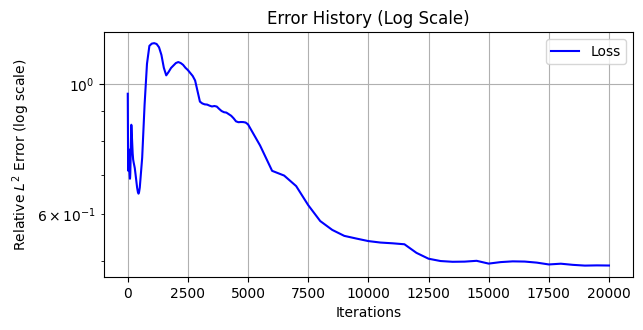

In [16]:
# Adjusting the plot to use a log scale for both loss and error
plt.figure(figsize=(12, 6))
# Plotting loss history with log scale
plt.subplot(2, 2, 1)
plt.plot(all_its, all_errors, label='Loss', color='blue')
plt.yscale('log')
plt.xlabel('Iterations')
plt.ylabel('Relative $L^2$ Error (log scale)')
plt.title('Error History (Log Scale)')
plt.grid(True)
plt.legend()

# Show the plots
plt.tight_layout()
plt.savefig(args.Name+'_Loss.png')
plt.show()


In [17]:
error = relative_l2(apply_fn(params, t, x), u_gt)
print(f'RL2 error: {error:.8f}') 

RL2 error: 0.49051124


Solution:


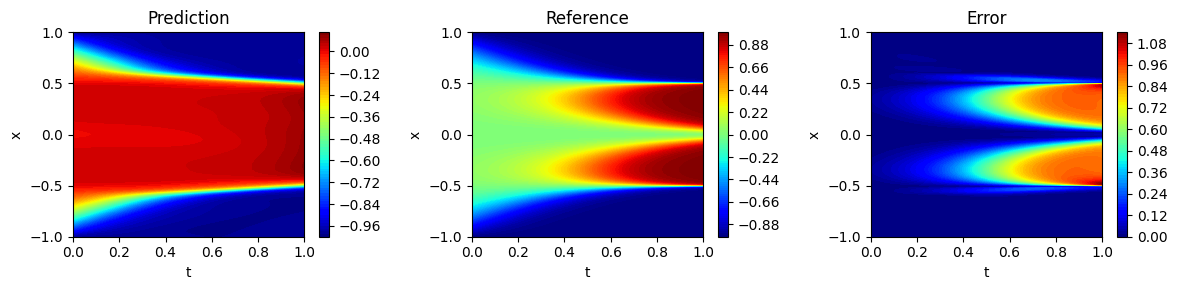

In [18]:
it=-1
print('Solution:')
u = apply_fn(params, t, x)
u = u.reshape(T.shape)
lambdas_grid=all_lambdas[it]
idx_it=all_idx[it]

# Plotting code
fig = plt.figure(figsize=(12, 3))
levels=100
# Scatter plot for collocation, initial, and boundary points
ax1 = fig.add_subplot(131)
contour = ax1.contourf(T, X, u, cmap='jet', levels=levels)  # Filled contour plot with 50 levels
fig.colorbar(contour)  # Add color bar to show scale
ax1.set_xlabel('t')
ax1.set_ylabel('x')
ax1.set_title('Prediction')

# Surface plot for Exact solution
ax2 = fig.add_subplot(132)
contour = ax2.contourf(T, X, Exact0, cmap='jet', levels=levels)  # Filled contour plot with 50 levels
fig.colorbar(contour)  # Add color bar to show scale
ax2.set_xlabel('t')
ax2.set_ylabel('x')
ax2.set_title('Reference')
# Surface plot for Exact solution
ax3 = fig.add_subplot(133)
contour = ax3.contourf(T, X, np.abs(Exact0-u), cmap='jet', levels=levels)  # Filled contour plot with 50 levels
fig.colorbar(contour)  # Add color bar to show scale
ax3.set_xlabel('t')
ax3.set_ylabel('x')
ax3.set_title('Error')
plt.tight_layout()

plt.savefig(args.Name+'Errorss_RBA-R.png',dpi=300)
plt.show()


## Cell 15: Preparation for Second-Order Optimization (SSBroyden)

This cell is the "handoff" step. It does not train the model, but performs the necessary conversions to switch from the `float32` Adam optimizer to the high-precision `float64` **SSBroyden** optimizer.

This transition is the core recommendation of the **SSBroyden paper**, which advocates for a hybrid Adam-then-SSBroyden strategy. This cell is the "then" part.

---
### Section 1: Parameter Flattening & Validation

* **Code:** `initial_weights, unflatten_func = ravel_pytree(params)`
* **What:** The `params` are a complex PyTree (a nested structure of dictionaries and arrays). Second-order optimizers like L-BFGS and SSBroyden cannot operate on this structure. They require a single, flat 1D vector of parameters.
    * `ravel_pytree` "flattens" the entire model into this 1D vector (`initial_weights`).
    * It also returns the `unflatten_func`, which is a "key" that knows how to turn the 1D vector back into the original PyTree.
* **Why:** This is a purely technical requirement for the optimizer.
* **The "Sanity Check":** The two `print(f'RL2 error: ...')` lines are a crucial validation step. They confirm that `flatten(params)` and then `unflatten(params)` results in the *exact same parameters* and the *exact same error*, proving the conversion is lossless.

---
### Section 2: Data Type Conversion to `float64`

* **Code:** `X=np.hstack([tc.astype(jnp.float64),xc.astype(jnp.float64)])`
* **What:** It converts all the training coordinates (`tc`, `xc`) from their original type (likely `float32`) to `float64` (double precision).
* **Why:** This is *mandatory* for second-order methods.
    * Adam (first-order) is robust and works well in `float32`.
    * SSBroyden (second-order) calculates approximations of the loss landscape's *curvature* (the Hessian). This is extremely sensitive to numerical precision. Running it in `float32` would lead to `NaN`s and numerical instability.

---
### Section 3: Resetting Hyperparameters

* **Code:** `gamma = args.gamma_bfgs`, `eta = 1-gamma`
* **What:** This re-initializes the `gamma` and `eta` variables.
* **Why:** This is a critical context switch.
    * The *old* `gamma` and `eta` were for the **vRBA framework** and **KKANs paper** EMAs (Cells 9 & 11).
    * These *new* `gamma` and `eta` are hyperparameters for the **SSBroyden optimizer** itself. They control the internal logic of its quasi-Newton update steps, not the vRBA weights.



In [19]:
gamma = args.gamma_bfgs
eta = 1-gamma
initial_weights, unflatten_func = ravel_pytree(params)
params_test=unflatten_func(initial_weights)
error = relative_l2(apply_fn(params, t, x), u_gt)
print(f'RL2 error: {error:.8f}') 
error = relative_l2(apply_fn(params_test, t, x), u_gt)
print(f'Reconstructed parameters: RL2 error: {error:.8f}') 
X=np.hstack([tc.astype(jnp.float64),xc.astype(jnp.float64)])

RL2 error: 0.49051124
Reconstructed parameters: RL2 error: 0.49051124



## Cell 16: Defining the Loss Functions for Second-Order Optimization

This cell defines the *new set of functions* required to execute the second phase of the hybrid optimization strategy: the **SSBroyden optimizer**.

A critical insight from the **SSBroyden paper** is that second-order methods (which build an approximation of the Hessian) require a *static and stable loss landscape*. The dynamic, per-iteration re-weighting from the **vRBA framework** and **KKANs paper** (used in Cell 11 for Adam) would destabilize these methods.

Therefore, this cell *deliberately* defines a new, simplified, and static loss function for the SSBroyden optimizer to use.

---
### Function 1: `apply_model_2nd_Order`

* **What it is:** This is the new, simplified loss function for the SSBroyden optimizer.
* **Key Changes from the Adam Loss (Cell 11):**
    1.  **No vRBA Weighting:** The PDE loss is now a standard, *unweighted* Mean Squared Error: `jnp.mean((residuals)**2)`. The dynamic `new_lambdas` are gone.
    2.  **No KKANs Global Weights:** The boundary condition loss is applied with a *static, hard-coded weight* (`10.0 * loss_bcs(params)`). The dynamic, gradient-norm-based `lamB` is gone.
* **Why:** This static loss function provides the stable landscape that second-order methods need to effectively minimize the error to high precision.

---
### Function 2: `update_lambdas`

* **What it is:** This function *only* updates the vRBA weights (`lambdas`).
* **Why is it separate?** The SSBroyden optimizer (which is often a `scipy.optimize` function) expects a loss function that returns *only one scalar value*: the loss. It cannot handle the auxiliary outputs (like `new_lambdas`) that our Adam-phase loss function (Cell 11) returned.
* **The New Workflow:** This function is refactored out. The training loop will now have to:
    1.  Call the SSBroyden optimizer (using `loss_and_gradient`) to update the `params`.
    2.  *Separately* call this `update_lambdas` function to prepare the weights for the *next* iteration's importance sampling (if used).

---
### Function 3: `loss_and_gradient`

* **What it is:** This is the "wrapper" or "glue" function that the SSBroyden optimizer will *actually call*.
* **Why:** This function solves the "flattening" problem from Cell 15.
* **The Process:**
    1.  The optimizer passes in a flat 1D vector (`weights`).
    2.  This function uses the `unflatten_func_arg` to "un-flatten" the vector back into the model's PyTree (`params_current`).
    3.  It calls `apply_model_2nd_Order` to get the simple, static loss value.
    4.  It returns *only* that scalar loss value, as required by the optimizer's API.
* **Note:** This function is designed to be passed to `jax.value_and_grad`. The optimizer will jit-compile `jax.value_and_grad(loss_and_gradient)` to get both the loss and the flat 1D gradient vector it needs for its update.



In [20]:
@partial(jax.jit, static_argnums=(0,))
def apply_model_2nd_Order(apply_fn, params, *train_data):
    t, x, ti, xi, ui = train_data
    def loss_pde(params):
        # Compute residuals
        residuals = PDE_residuals(params, t, x, apply_fn)
        pde_loss = jnp.mean((residuals)**2)
        return pde_loss
    def loss_bcs(params):
        # Compute initial condition loss
        u_pred = apply_fn(params, ti, xi)
        ics_loss = jnp.mean((ui - u_pred) ** 2)
        return ics_loss
    def loss(params):
        return loss_pde(params)+10.0*loss_bcs(params)
    loss_value=loss(params)
    return loss_value

In [21]:
@partial(jax.jit, static_argnums=(0,))
def update_lambdas(apply_fn,params,lambdas,gamma,eta,tc,xc,it):
    t,x=tc,xc
    def get_lambdas(params, lambdas):
        residuals = PDE_residuals(params, t, x, apply_fn)
        # Update lambdas
        r_i_norm = lax.stop_gradient(jnp.abs(residuals))
        new_lambdas = update_weights_fn(r_i_norm,lambdas, it, 
                                          gamma=gamma,
                                          eta=eta)
        return new_lambdas
    new_lambdas=get_lambdas(params, lambdas)
    return new_lambdas

In [22]:
@partial(jax.jit, static_argnums=(1, 2))
def loss_and_gradient(weights, N_arg, unflatten_func_arg, *train_data_tuple_arg):
    flat_jax_array = weights 
    params_current = unflatten_func_arg(flat_jax_array)
    loss_val_jax = apply_model_2nd_Order(N_arg, params_current, *train_data_tuple_arg)
    return loss_val_jax


## Cell 17: The SSBroyden Optimization Step Function

This is the core function that executes one "macro-step" of the second-order optimization. It is the practical implementation of the hybrid strategy from the **SSBroyden paper**, but it is powered by two other key innovations:

1.  **Custom Optimizer:** The `minimize` function being called is *not* SciPy. It is the project's custom, JAX-native implementation of the SSBroyden optimizer (as detailed in the appendix of the **vRBA framework** paper). This is a highly sensitive, purpose-built function for this exact workflow.
2.  **Hybrid vRBA-SSBroyden:** This step is *not* a simple optimization. It hybridizes the **vRBA framework** with the **SSBroyden** optimizer in a sophisticated way.

---
### Section 1: The Hybrid vRBA-SSBroyden Workflow

This function's logic follows a clear, three-part process that intelligently combines both papers:

1.  **Update vRBA Weights (vRBA framework):**
    * `updated_lambdas = update_lambdas(...)`
    * First, it calls the `update_lambdas` function (from Cell 16) to get the *new* vRBA attention weights based on the model's current state.

2.  **Resample Points (vRBA framework):**
    * `_ , current_train_data_tuple = sample_points_pdf(...)`
    * Second, it immediately uses those new weights to perform **importance sampling** (via the function from Cell 12).
    * This is the key insight: **It uses the vRBA framework to intelligently select the *most important* batch of points** to feed to the optimizer.

3.  **Run Optimizer (SSBroyden paper):**
    * `result = minimize(...)`
    * Finally, it runs the powerful `SSBroyden` optimizer *only on this new, high-value batch of points*.
    * It uses the static, unweighted loss function (`loss_and_gradient` from Cell 16) because the "weighting" has already been applied via the *sampling* itself.

---
### Section 2: Hessian Recycling (A Key Optimization)

This entire section is a critical performance optimization that makes the SSBroyden method "warm-started" and efficient.

* **Code:** `new_H0 = result.hess_inv`
* **What:** The `result` from the optimizer contains its *final* computed approximation of the inverse Hessian (`hess_inv`). This line extracts it.
* **Why:** The loss landscape's curvature (the Hessian) doesn't change dramatically from one step to the next. This code "recycles" the final Hessian from the *current* step to be used as the *initial* Hessian guess (`initial_H`) for the *next* step. This gives the optimizer a massive head-start.

* **Code:** `L = jnp.linalg.cholesky(new_H0)`
* **What:** This is a **stability guardrail**. It checks if the recycled Hessian is still valid (i.e., positive-definite).
* **Why:** If the optimization process produces a bad Hessian (e.g., due to numerical precision), it could fail.
    * The `try...except` and `jax.lax.cond` block ensures that if the check fails, the Hessian is *safely reset* to an identity matrix (`jnp.eye`).
    * This prevents the entire training run from crashing and allows the optimizer to "start fresh" on the next step.



In [23]:

@partial(jax.jit, static_argnames=("apply_fn", "unflatten_func", "batch_size", "gamma", "eta", "k", "c", "static_options"))
def SSBroyden_step(
    initial_weights, H0, key,
    tc, xc, lambdas,
    apply_fn, unflatten_func, batch_size, gamma, eta, k, c, static_options,it,
    ti, xi, ui ):
    key, subkey = jax.random.split(key)
    # 2. Update Lambdas ...
    params_it = unflatten_func(initial_weights)
    updated_lambdas = update_lambdas(apply_fn, params_it, lambdas, gamma, eta, tc, xc,it)
    _ , current_train_data_tuple = sample_points_pdf(
        subkey, batch_size, updated_lambdas, tc, xc, ti, xi, ui, k, c
    )
    # 4. Prepare the full options dictionary for minimize
    current_options = dict(static_options)
    current_options['initial_H'] = H0
    # 5. Run the SSBroyden optimization for Nchange steps
    result = minimize(
        fun=loss_and_gradient,
        x0=initial_weights,
        args=(apply_fn, unflatten_func, *current_train_data_tuple),
        method='BFGS', # SSBroyden version of BFGs
        options=current_options)
    # 6. Recycle the Hessian purely
    new_H0 = result.hess_inv
    new_H0 = (new_H0 + jnp.transpose(new_H0)) / 2
    try:
        L = jnp.linalg.cholesky(new_H0)
        is_failed = jnp.any(jnp.isnan(L))
        final_H0 = jax.lax.cond(
            is_failed,
            lambda op: jnp.eye(op.shape[0], dtype=op.dtype),
            lambda op: op,
            operand=new_H0)
    except LinAlgError:
        final_H0 = jnp.eye(new_H0.shape[0], dtype=new_H0.dtype)
    return result.x, final_H0, key, result.fun, result.nit, updated_lambdas

## Cell 18: Main SSBroyden Training Loop

This cell is the "engine" for the *second and final* stage of the hybrid optimization strategy. Just as Cell 13 was the conductor for the "Adam phase," this cell is the conductor for the **SSBroyden** phase.

Its sole purpose is to repeatedly call the `SSBroyden_step` function (from Cell 17) to refine the model's parameters to high precision.

---
### Section 1: The "Macro-Step" Workflow (Hybridizing SSBroyden and vRBA)

This loop's design is the key to hybridizing the **SSBroyden optimizer** with the **vRBA framework**. It's a "loop-within-a-loop" (or "macro-step") workflow:

* **Outer Loop (This Cell):** This `for it in pbar:` loop runs for `num_outer_iterations`. This is the "Macro-Step" loop.
* **Inner Loop (Cell 17):** Inside `SSBroyden_step`, the `minimize` function is called and runs for `Nchange` iterations. This is the "Micro-Step" loop.

This "Optimize-Pause-Resample" workflow is critical:
1.  **Optimize (SSBroyden):** `SSBroyden_step` is called. It runs the `minimize` function for `Nchange` "micro-steps" on a *static* batch of data, allowing the optimizer to converge on a stable loss landscape.
2.  **Pause (This Cell):** The `minimize` function finishes, and `SSBroyden_step` returns the new `initial_weights` and `H0`.
3.  **Resample (vRBA):** On the *next* iteration of this *outer loop*, the `SSBroyden_step` function is called again. As we saw in Cell 17, the *first thing it does* is call `update_lambdas` and `sample_points_pdf` to create a *new, re-weighted batch* of data.

This brilliantly combines both papers: The **SSBroyden optimizer** gets the static batch it needs (for `Nchange` steps), while the **vRBA framework** gets to periodically update the sampling distribution to focus the optimizer on the *next* set of high-error regions.

---
### Section 2: Hessian Recycling & State Management

* **`H0 = jnp.eye(...)`**: The initial Hessian `H0` is initialized *once* as an identity matrix before the loop *starts*.
* **`initial_weights, H0, key, ... = SSBroyden_step(...)`**: This line is the core of the state management.
    * The current `initial_weights` and `H0` are passed *into* `SSBroyden_step`.
    * The *new* weights and the *recycled* Hessian (`H0`) are returned.
    * This "Hessian Recycling" (passing the final Hessian from one step as the initial Hessian for the next) is a key performance optimization from the **SSBroyden paper** that makes the optimizer "warm-started."

---
### Section 3: Logging & Metrics

* **`effective_steps=effective_steps+nit`**: This tracks the *true* number of gradient evaluations. `nit` is the number of "micro-steps" (inner iterations) the optimizer *actually* took in the last `SSBroyden_step`.
* **`all_its.append(effective_steps+Adam_Steps)`**: This appends the *total* cumulative step count, so the final error plot will show a continuous line from the end of the Adam phase.
* **`all_errors.append(error)`**: The final `L_2` and `L_infty` errors are calculated and logged after each "macro-step" to track the high-precision convergence.
"""

In [24]:
# Initialize the Hessian
H0 = jnp.eye(len(initial_weights), dtype=jnp.float64)
num_outer_iterations = Nbfgs // Nchange
## SSBroyden Hyperparameters
static_options = static_options_SSBroyden
static_options['maxiter']=Nchange
static_options_tuple = tuple(static_options.items())
# Training
pbar = tqdm(range(num_outer_iterations), desc="SSBroyden Training")
effective_steps=0
Adam_Steps=all_its[-1]
for it in pbar:
    initial_weights, H0, key, loss_val, nit, lambdas = SSBroyden_step(
        initial_weights, H0, key,
        tc, xc, lambdas,
        apply_fn, unflatten_func, batch_size, gamma, eta, k_samp_bfgs, c_samp_bfgs,
        static_options_tuple,it,
        ti, xi, ui
    )
    effective_steps=effective_steps+nit
    current_params_for_eval = unflatten_func(initial_weights)
    u_pred_it=apply_fn(current_params_for_eval, t, x)
    error = relative_l2(u_pred_it, u_gt)
    error_vec = u_pred_it - u_gt
    L_infty = scipy.linalg.norm(error_vec.flatten(), ord=np.inf)
    L_2 = scipy.linalg.norm(error_vec.flatten(), ord=2)
    all_errors.append(error)
    all_loss.append(loss_val)
    all_its.append(effective_steps+Adam_Steps)
    all_L_infty.append(L_infty)
    all_L_2.append(L_2)
    pbar.set_postfix({
        'It': effective_steps,
        'Loss': f'{loss_val:.3e}',
        'RL2': f'{float(error):.3e}',
        'lam_min': f'{jnp.min(lambdas):.3e}',
        'lam_max': f'{jnp.max(lambdas):.3e}',
    }) 

SSBroyden Training: 100%|██████████| 1000/1000 [02:24<00:00,  6.93it/s, It=66596, Loss=2.721e-12, RL2=3.148e-06, lam_min=9.992e-04, lam_max=9.003e-01]



## Cell 19: Final Visualization & Error Reporting

This is the final cell, which serves as the "results" section for the entire experiment. It generates two key figures to validate the success of the full, hybrid optimization run.

1.  A three-panel plot comparing the final **Prediction**, the **Reference** solution, and the **Absolute Error**.
2.  A log-scale plot of the **Error History** across the *entire* training run (both Adam and SSBroyden phases).

---
### Section 1: Final Solution Plots (Prediction vs. Reference vs. Error)

This section generates the primary visual output of the model's final, high-precision solution, which was computed by the SSBroyden loop (Cell 18).

* **`u = apply_fn(current_params_for_eval, ...)`**: Gets the final prediction using the parameters returned from the SSBroyden loop.
* **Key Plotting Tactic 1: `shared_levels`**
    * **Code:** `global_vmin = ...`, `shared_levels = ...`, `contourf(..., levels=shared_levels)`
    * **Why:** This is a critical data visualization technique. It calculates the *global* min/max across *both* the prediction and the reference. By forcing both plots to use the same `shared_levels`, it ensures their color bars are identical. This allows for a fair, direct, "apples-to-apples" visual comparison.
* **Key Plotting Tactic 2: `LogNorm`**
    * **Code:** `log_norm = colors.LogNorm(...)`, `pcolormesh(..., norm=log_norm)`
    * **Why:** The 'Error' plot is rendered on a *logarithmic color scale*. This is essential for high-precision problems. On a standard linear scale, an error of `1e-8` and `1e-5` would both look black (zero). The log scale makes these tiny, high-precision errors visible.

---
### Section 2: Error History Plot (The "Proof" of the Hybrid Strategy)

This second figure is the most important plot for validating the core theory of the **SSBroyden paper**.

* **Code:** `plt.plot(all_its, all_errors, ...)`
* **Why:** This plots the `all_errors` list, which contains the error history from *both* the Adam phase (Cell 13) and the SSBroyden phase (Cell 18).
* **What it Shows:** This plot is the "smoking gun" of the hybrid strategy. It will typically show:
    1.  The error decreasing rapidly and then *plateauing* during the Adam phase.
    2.  A sharp, sudden *drop* (a "second wind") at the iteration where the SSBroyden loop (Cell 18) took over.
    
This visualization proves the **SSBroyden paper's** central claim: that the first-order Adam optimizer finds a good "basin," and the second-order SSBroyden optimizer then refines the solution within that basin to a much higher level of precision.

* **Code:** `print('Minimum achieved error:',...)`
* **Why:** This prints the final, single scalar metric that quantifies the success of the entire, combined (vRBA + KKANs + SSBroyden) framework.
"""


In [25]:
T, X = np.meshgrid(t0, x0)
# Ground Truth (already float64 due to T, X)
t = T.flatten()[:,None]
x = X.flatten()[:,None]
u_gt = Exact0.flatten()[:,None]
it=-1
print('Solution:')
u = apply_fn(current_params_for_eval, t, x)
u = u.reshape(T.shape)

Solution:


Solution:


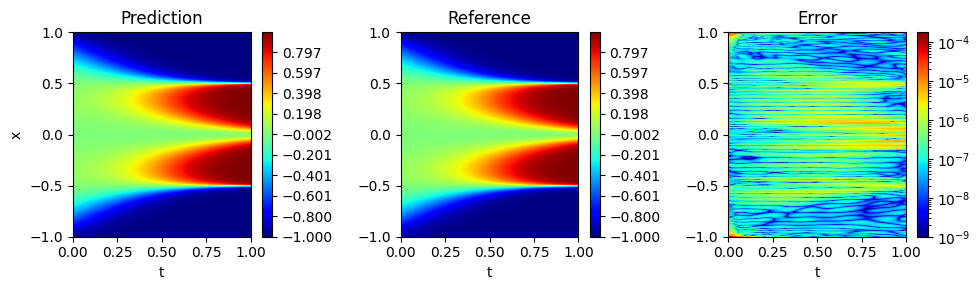

In [26]:
it=-1
print('Solution:')
# --- 1. Find the global vmin and vmax across BOTH datasets ---
global_vmin = np.min([u, Exact0])
global_vmax = np.max([u, Exact0])
# --- 2. Create a shared array of contour levels ---
num_levels = 500
shared_levels = np.linspace(global_vmin, global_vmax, num_levels)
# Plotting code
fig = plt.figure(figsize=(10, 3))
# --- Plot for Prediction (using the shared levels array) ---
ax1 = fig.add_subplot(131)
contour1 = ax1.contourf(T, X, u, cmap='jet', 
                        levels=shared_levels) # 
fig.colorbar(contour1, ax=ax1)
ax1.set_xlabel('t')
ax1.set_ylabel('x')
ax1.set_title('Prediction')
# --- Plot for Reference Solution (using the shared levels array) ---
ax2 = fig.add_subplot(132)
contour2 = ax2.contourf(T, X, Exact0, cmap='jet', 
                        levels=shared_levels) #
fig.colorbar(contour2, ax=ax2)
ax2.set_xlabel('t')
#ax2.set_ylabel('x')
ax2.set_title('Reference')
# --- Plot for Error (this part is separate and correct) ---
ax3 = fig.add_subplot(133)
error_data = np.abs(Exact0-u)
log_norm = colors.LogNorm(vmin=1e-9, vmax=error_data.max())

mesh3 = ax3.pcolormesh(T, X, error_data, 
                       cmap='jet', 
                       norm=log_norm,
                       shading='gouraud')
fig.colorbar(mesh3, ax=ax3)
ax3.set_xlabel('t')
ax3.set_title('Error')

plt.tight_layout()
plt.savefig(args.Name+'Errors_RBA_SSBroyden.png',dpi=300)
plt.show()

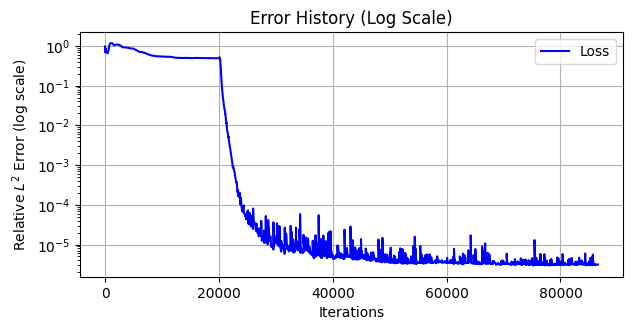

In [27]:
# Adjusting the plot to use a log scale for both loss and error

plt.figure(figsize=(12, 6))

# Plotting loss history with log scale
plt.subplot(2, 2, 1)
plt.plot(all_its, all_errors, label='Loss', color='blue')


#plt.xscale('log')
plt.yscale('log')
plt.xlabel('Iterations')
plt.ylabel('Relative $L^2$ Error (log scale)')
plt.title('Error History (Log Scale)')
plt.grid(True)
plt.legend()
# Show the plots
plt.tight_layout()
plt.savefig(args.Name+'_Loss.png')
plt.show()


In [28]:
print('Minimum achieved error:',np.nanmin(all_errors))

Minimum achieved error: 2.949726418814049e-06


## Cell 20: Save Experiment Results to .mat File

This is the final "epilogue" cell of the entire notebook. Its sole purpose is to **persist the results** of the complete training run.

---
### Section 1: Data Aggregation

* **`results_dict = { ... }`**: This code collects all the Python lists that were meticulously logged during both the Adam training loop (Cell 13) and the SSBroyden training loop (Cell 18).
* **What it saves:**
    * **Error Metrics:** `all_errors`, `all_L_infty`, `all_L_2` (the history of convergence).
    * **Iteration Counts:** `all_its` (the timeline of the run).
    * **Loss History:** `all_loss` (the raw loss values).
    * **Internal Algorithm Parameters:** `all_gamma`, `all_lamB`, `all_max_RBA` (key hyperparameters that were tracked, useful for debugging and analysis).

---
### Section 2: Data Persistence

* **`scipy.io.savemat(..., results_dict)`**: This command saves the entire Python dictionary into a single `.mat` file.
* **Why:** This is the scientific deliverable of the experiment.
    1.  **Reproducibility:** It allows the researcher to analyze the results and create new plots without re-running the entire, computationally expensive model.
    2.  **Portability:** The `.mat` file format is a standard that can be easily loaded and analyzed by other tools (like MATLAB) or other Python scripts.
"""


In [29]:
results_dict = {
    'model_name': args.Name,
    'all_errors': all_errors,
    'all_its': all_its,
    'all_loss': all_loss,
    'all_gamma': all_gamma,
    'all_lamB': all_lamB,
    'all_max_RBA': all_max_RBA,
    'all_L_infty':all_L_infty,
    'all_L_2':all_L_2,
}
# Save dictionary as a .mat file
scipy.io.savemat(args.Name + 'Log_files_SSBroyden.mat', results_dict)